# Interpolation using LagRBF on a 2-dimensional square domain

This notebook presents the simplest way of using LagRBF by interpolating a function in a 2-dimensional square domain.
To keep it simple, the proposed example runs on a single MPI rank, but the same code can be used on multiple MPI ranks, the only exception being the plotting functions that should not be called on every process.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import lagrbfpy as lf
from petsc4py import PETSc

## Analytical function
Let's start by defining a class that will host the analytical function we will use for the interpolation example.
Note that you can easily add more functions to play with it.
In this example we will use a simple Gaussian function.

In [21]:
class AnalyticalFunctions:
  def __init__(self, coords:np.ndarray):
    self.coords = coords
    return

  def gaussian(self, sigma:float=0.1) -> np.ndarray:
    return np.exp(-np.sum(self.coords**2, axis=1)/(2*sigma**2))

### MPI Communicator
Although we run this example on a single rank, we need the communicator because all LagRBF functions are made to run in parallel.

In [22]:
# PETSc MPI communicator
comm = PETSc.COMM_WORLD

## Data from a uniform structured grid
To keep it simple, here we will define our data points on a structured uniform grid. 
Note however that this is absolutely **not a requirement** for the method to be used. 
Data points can have a completely arbitrary distribution, the only constraint is that two different points cannot occupy the same position in space.

In [23]:
# Domain definition
Origin = np.array([-1, -1], dtype=np.float64)
End    = np.array([ 1,  1], dtype=np.float64)
# Number of points in each dimension
ndata = np.array([32, 32], dtype=np.int32)

We use the class [PointSwarm]() to generate the set of point. 
Although it might seem overkill to use a custom class to generate a uniform structured grid, this class actually handles point generation in parallel (hence the argument `comm`)

In [33]:
swarm_data = lf.PointSwarm(
  comm=comm,
  O=Origin, L=End, n=ndata,
  point_type="structured",
  coordinate_type="cartesian"
)

# Create an instance of the AnalyticalFunctions class with the swarm data points
funcs = AnalyticalFunctions(swarm_data.points)
# evaluate the Gaussian function at the swarm data points
swarm_data.point_data["gaussian"] = funcs.gaussian(sigma=0.5)

### Plot the points and the function evaluated at these points
We created points organized as a structured uniform grid. But function values are actually only evaluated at these points coordinates.
Therefore, the function representation is discrete. That's what we observe when we use the `scatter()` method: the function values evaluated at discrete points.

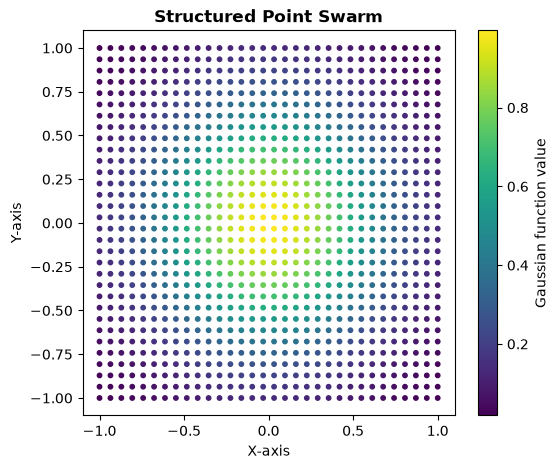

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
c = ax.scatter(
  swarm_data.points[:, 0], 
  swarm_data.points[:, 1], 
  c=swarm_data.point_data["gaussian"], 
  cmap='viridis', 
  s=10, 
  label='Gaussian Function'
)
ax.set_title('Structured Point Swarm', fontweight='bold')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
plt.colorbar(c, ax=ax, label='Gaussian function value')
plt.show()
plt.close(fig)

### Plot the function value on a meshed grid
Because these points actually form a structured grid we can represent them as a mesh. Matplotlib conveniently interpolate values of the function between mesh nodes to represent a continuous field. To explore the effects of the interpolation on the function representation between mesh nodes see [this matplotlib tutorial](https://matplotlib.org/stable/gallery/images_contours_and_fields/interpolation_methods.html).

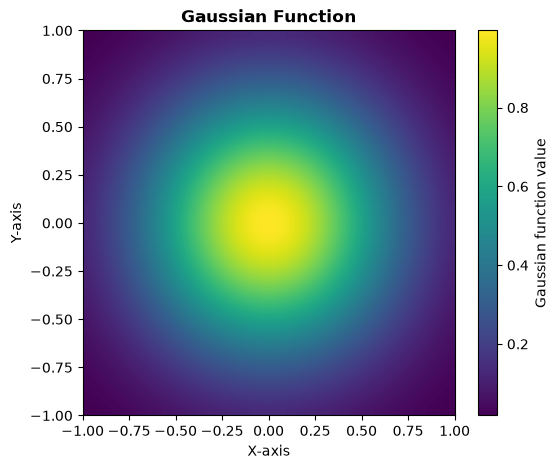

In [51]:
fig, ax = plt.subplots(figsize=(6, 5))
X = swarm_data.points[:, 0].reshape(ndata)
Y = swarm_data.points[:, 1].reshape(ndata)
# Reshape the Gaussian function values to match the grid shape
Z = swarm_data.point_data["gaussian"].reshape(ndata)
c = ax.imshow(
  Z, 
  extent=(Origin[0], End[0], Origin[1], End[1]), 
  origin='lower', 
  cmap='viridis', 
  aspect='auto',
  interpolation='bilinear' # Change it to experiment the effect of interpolation methods on the visualization
)
ax.set_title('Gaussian Function', fontweight='bold')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
plt.colorbar(c, ax=ax, label='Gaussian function value')
plt.show()

## Interpolation points
Let's now create points on which we want to interpolate the function values.
This time let's generate points with an unstructured distribution.
See [Halton]() point distribution for further details.

In [49]:
ninterp = np.int32(64**2)
swarm_interp = lf.PointSwarm(
  comm=comm,
  O=Origin, L=End, n=ninterp,
  point_type="halton",
  coordinate_type="cartesian",
  bases=[2,3,5]
)

Let's have a look at how these points are distributed

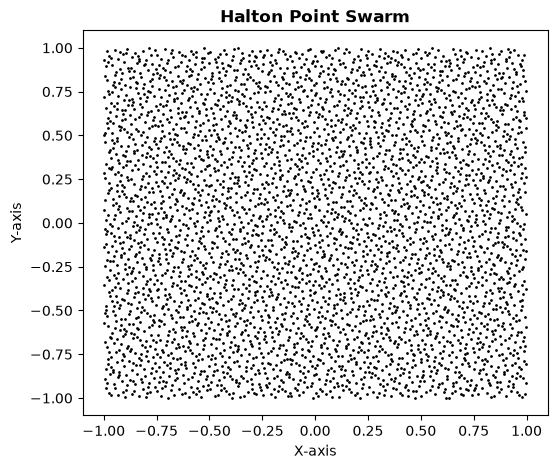

In [62]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(swarm_interp.points[:, 0], swarm_interp.points[:, 1], 'k.', markersize=2)
ax.set_title('Halton Point Swarm', fontweight='bold')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
plt.show()
plt.close(fig)

## Interpolation

We use a Python's data class to store coordinates and values that we will use for interpolation.

> [!Note] 
> In this example we use a single field, but the method can interpolate any number of fields at once. For further details see available scripts in `python_api/scripts`

In [53]:
# number of fields to interpolate
nfields = 1
# data container for the swarm data points and their associated values
data = lf.PointContainer(
  coords=swarm_data.points[:, :2],
  values=np.column_stack([swarm_data.point_data[f] for f in swarm_data.point_data]),
)
# point container for the interpolation points
points = lf.PointContainer(
  coords=swarm_interp.points[:, :2],
)
# Create a point container for the output of the interpolation 
output = lf.PointContainer(
  coords=np.zeros((ninterp, 2), dtype=np.float64),
  values=np.zeros((ninterp, nfields), dtype=np.float64),
  pidx=np.zeros((ninterp,), dtype=np.int64)
)

### Interpolation class
Now we are ready to dive into the interpolation.
First we will create the class instance that will be used for the RBF interpolation.

Here we define the size of the domain, note that all the points must be contained inside the domain, if a point is outside an error will be raised.

Then the number of partitions in the domain. This number influences how the domain is discretized into subdomains to fasten the interpolation process. Of course, a good friend of mine would say "there's no free lunch", so speed-up comes at a cost of accuracy. It is up to you how much you agree to pay to make it faster. You can experience by varying the number of partitions to see how it impacts the rapidity versus accuracy of the interpolation. 

You can also experiment with the `overlap` and `shape_fac` values to see how they impact the result.

As for the kernel, `2` stands for the Wendland's C2 function. Although this function is not always the best (in some cases other kernels can perform better), it has a very good adaptability to a very wide class of problem. 


In [78]:
ctx = lf.LagRBFInterpolator(
  dim = 2,
  minCoords=Origin-0.01*(End-Origin),
  maxCoords=End+0.01*(End-Origin),
  npartitions=np.array([4, 4], dtype=np.int32),
  nfields=nfields,
  kernel = 2,
  overlap = 1.1,
  shape_fac = 0.25
)


  ░██                               ░█████████  ░████████   ░██████████
  ░██                               ░██     ░██ ░██    ░██  ░██        
  ░██          ░██████    ░████████ ░██     ░██ ░██    ░██  ░██        
  ░██               ░██  ░██    ░██ ░█████████  ░████████   ░█████████ 
  ░██          ░███████  ░██    ░██ ░██   ░██   ░██     ░██ ░██        
  ░██         ░██   ░██  ░██   ░███ ░██    ░██  ░██     ░██ ░██        
  ░██████████  ░█████░██  ░█████░██ ░██     ░██ ░█████████  ░██        
                                ░██                                    
                          ░███████                                     

———————————————————————————————————————————————————————————————————————
 LagRBF: Lagrangian points Radial Basis Function library
    git url: https://github.com/anthony-jourdon/LagRBF
** AVX detected - optimized kernels will be used.
———————————————————————————————————————————————————————————————————————
[[ PartitionOfUnityCreate ]]
Solve method se

### Interpolate
Now we can simply interpolate using the following function. 
> [!Note] 
> Successive interpolations can be performed using the same `ctx` by changing the contents of data for example if function values or points coordinates change.


In [79]:
ctx.interpolate(
  data=data,
  points=points,
  output=output
)

[[ SwarmFieldAssignUniqueIndex ]]
[[ DMSwarmAssignMigrateBasic ]]
[[ SwarmDataAssignMigrateDuplicateGhostPoints ]]
[[ SwarmFieldAssignUniqueIndex ]]
[[ DMSwarmAssignMigrateBasic ]]
[[ SwarmInterpSetWeights_AVX256 ]]
[[ LagRBF_PartitionsSetUp ]]
[[ PointwiseInterpolation_AVX256 ]]
[[ LagRBF_PartitionsReset ]]


### Plot interpolation result

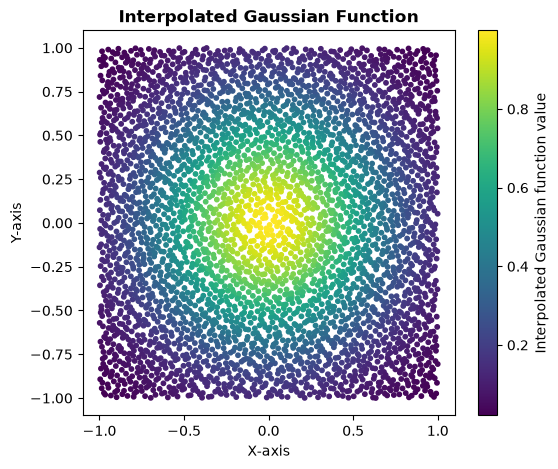

In [80]:
fig, ax = plt.subplots(figsize=(6, 5))
c = ax.scatter(
  output.coords[:, 0], 
  output.coords[:, 1], 
  c=output.values[:, 0], 
  cmap='viridis', 
  s=10, 
  label='Interpolated Gaussian Function'
)
ax.set_title('Interpolated Gaussian Function', fontweight='bold')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
plt.colorbar(c, ax=ax, label='Interpolated Gaussian function value')
plt.show()
plt.close(fig)

We can easily measure the error since we have an analytical function

In [81]:
analytical_values = AnalyticalFunctions(output.coords).gaussian(sigma=0.5)
diff = np.abs(output.values[:, 0] - analytical_values)
l2_error = np.sqrt(np.mean(diff**2))
linf_error = np.max(diff)
print(f"L2 error: {l2_error:.6e}, Linf error: {linf_error:.6e}")

L2 error: 6.585958e-05, Linf error: 3.538513e-04


We can also plot where errors are the largests

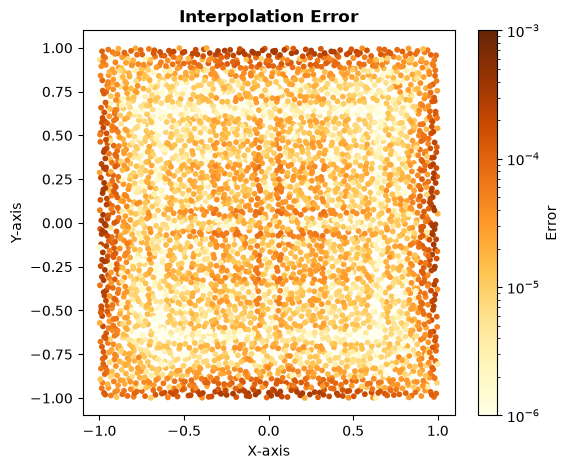

In [82]:

from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(6, 5))
c = ax.scatter(
  output.coords[:, 0], 
  output.coords[:, 1], 
  c=diff, 
  cmap='YlOrBr', 
  s=10,
  norm=LogNorm(vmin=1e-6, vmax=1e-3)
)
ax.set_title('Interpolation Error', fontweight='bold')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
plt.colorbar(c, ax=ax, label='Error')
plt.show()
plt.close(fig)

As we can expect, the largest errors are located near the boundaries of the domain where there are less available data.

Finally, don't forget to destroy the object to clear memory.

In [83]:
del ctx